# 02 - Match & Normalize (split-controllable)

Pick a **train union** and **held-out test** via globals, build the common gene/protein space, fit
**harmonization on the train union only**, apply it frozen to every dataset (train + test), optionally
apply a **model representation** (z-score / binning / ranking), save the per-split matrices the HPC
pipeline consumes, save all learned parameters, and render **Nature-style before/after** figures.

**Harmonization is literature-standard and leakage-safe.** For cross-platform ML training, quantile /
rank / z transforms fit on the *training* data and applied to the held-out set as a fixed reference are
the validated approach (Thompson et al. 2020, *Genome Biol*; batch-correction tools like ComBat are
avoided because they cannot be frozen and applied to a held-out platform). The reference here is the
**train union**, so no held-out labels or distributions inform the transform.

Run this notebook once per split (change `TRAIN_DATASETS` / `TEST_DATASETS`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, joblib
sys.path.append(str(Path.cwd().parent / "src"))
import harmonize as H
import normalization as N
import plotting as PL

# ============================ GLOBALS (edit these) ============================
LOADED_DIR = Path("../data/loaded")     # from notebook 00
SPLITS_DIR = Path("../data/splits")

# ---- the four splits you asked for; set ONE active at a time ----
# 1) ["CCLE","TMT"]                -> ["iTRAQ","LabelFree"]
# 2) ["CCLE","TMT","iTRAQ"]        -> ["LabelFree"]
# 3) ["CCLE","TMT","LabelFree"]    -> ["iTRAQ"]
# 4) ["CCLE","LabelFree","iTRAQ"]  -> ["TMT"]
TRAIN_DATASETS = ["CCLE", "TMT", "iTRAQ"]
TEST_DATASETS  = ["LabelFree"]

# ---- harmonization (cross-dataset alignment), fit on TRAIN UNION ----
# "quantile_normal" (recommended, literature-standard) | "robust_z" | "standard_z"
HARMONIZATION_METHOD = "quantile_normal"
RNA_TRANSFORM   = None          # CCLE RNA already log2(TPM+1); "log2p1" if raw counts
PROT_TRANSFORM  = "asinh"       # stabilizes MS ratio/intensity tails

# ---- model representation applied to genes (fit on train union) ----
# "zscore" | "binning" | "ranking" | "none"  -- this is the axis you sweep
MODEL_NORM = "zscore"
N_BINS = 50

SPLIT_NAME = "_".join(d.lower() for d in TRAIN_DATASETS) + "__" + "_".join(d.lower() for d in TEST_DATASETS)
SPLIT_DIR  = SPLITS_DIR / SPLIT_NAME
FIG_DIR    = Path("../results/figures") / SPLIT_NAME
SPLIT_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)
print("SPLIT:", SPLIT_NAME); print(" train:", TRAIN_DATASETS, "-> test:", TEST_DATASETS)
print(" harmonization:", HARMONIZATION_METHOD, "| model_norm:", MODEL_NORM)

SPLIT: ccle_tmt_itraq__labelfree
 train: ['CCLE', 'TMT', 'iTRAQ'] -> test: ['LabelFree']
 harmonization: quantile_normal | model_norm: zscore


## 1. Load datasets (from notebook 00; synthetic fallback if absent)

In [2]:
ALL = list(dict.fromkeys(TRAIN_DATASETS + TEST_DATASETS))
def load_or_synth(name):
    xp = LOADED_DIR / f"{name}_rna.joblib"; yp = LOADED_DIR / f"{name}_protein.joblib"
    if xp.exists() and yp.exists():
        return joblib.load(xp), joblib.load(yp)
    rng = np.random.default_rng(abs(hash(name)) % 2**32)   # synthetic fallback
    n = {"CCLE":120,"TMT":60,"iTRAQ":40,"LabelFree":45}.get(name,50)
    genes=[f"P{i:03d}" for i in range(20)]+[f"G{i:04d}" for i in range(180)]; prots=[f"P{i:03d}" for i in range(20)]
    sc={"CCLE":1,"TMT":1.4,"iTRAQ":.7,"LabelFree":3}.get(name,1); sh={"CCLE":0,"TMT":.5,"iTRAQ":-.4,"LabelFree":2}.get(name,0)
    W={p:rng.normal(size=6) for p in prots}; drv={p:rng.choice(len(genes),6,False) for p in prots}
    X=pd.DataFrame(rng.normal(sh,sc,(n,len(genes))),index=[f"{name}_s{i}" for i in range(n)],columns=genes)
    Y=pd.DataFrame(index=X.index,columns=prots,dtype=float)
    for p in prots: Y[p]=X.iloc[:,drv[p]].to_numpy()@W[p]+rng.normal(scale=.5,size=n)
    return X,Y
raw={d:dict(zip(["RNA","Protein"],load_or_synth(d))) for d in ALL}
for d in ALL:
    raw[d]["RNA"].index=[f"{d}::{s}" for s in raw[d]["RNA"].index]
    raw[d]["Protein"].index=[f"{d}::{s}" for s in raw[d]["Protein"].index]
    c=raw[d]["RNA"].index.intersection(raw[d]["Protein"].index)
    raw[d]["RNA"]=raw[d]["RNA"].loc[c]; raw[d]["Protein"]=raw[d]["Protein"].loc[c]
    print(f"{d:10s} RNA {raw[d]['RNA'].shape} Protein {raw[d]['Protein'].shape}")

CCLE       RNA (369, 22614) Protein (369, 5113)
TMT        RNA (1924, 15001) Protein (1924, 6885)
iTRAQ      RNA (276, 14521) Protein (276, 4994)
LabelFree  RNA (360, 14947) Protein (360, 2563)


## 1b. ID harmonization + overlap diagnosis (run this if section 3 raised an empty-reference error)

Different sources label features differently (uppercase gene symbols vs lowercase, Ensembl IDs with
version suffixes, UniProt accessions). If the common gene/protein intersection is empty, harmonization
fails with *"0 features"*. Set `CLEAN_IDS=True` to apply a uniform symbol cleanup, then inspect where the
intersection collapses. If proteins are UniProt in one source and symbols in another, map them to a common
namespace in your loader (notebook 00) before this point.

In [3]:
import importlib, harmonize
importlib.reload(harmonize)
import harmonize as H
print(hasattr(H, "map_ensembl_columns_to_symbol"))   # must print True

True


In [4]:
CLEAN_IDS = True   # uppercase + strip Ensembl version suffixes on gene/protein IDs
MAP_PROTEIN_ENSEMBL_TO_SYMBOL = True   # CPTAC proteins are Ensembl gene IDs; map to CCLE symbols

# Load the Ensembl->symbol map saved by notebook 00 (falls back to empty).
id2sym = {}
_map_path = LOADED_DIR / "id2sym.joblib"
if _map_path.exists():
    id2sym = joblib.load(_map_path)
    print(f"loaded id2sym: {len(id2sym)} entries")
else:
    print("id2sym.joblib not found; protein Ensembl->symbol mapping skipped. "
          "Re-run notebook 00, or provide the mapping.")

if MAP_PROTEIN_ENSEMBL_TO_SYMBOL and id2sym:
    for d in ALL:
        raw[d]["Protein"] = H.map_ensembl_columns_to_symbol(raw[d]["Protein"], id2sym)

if CLEAN_IDS:
    for d in ALL:
        raw[d]["RNA"].columns     = H.normalize_symbols(raw[d]["RNA"].columns)
        raw[d]["Protein"].columns = H.normalize_symbols(raw[d]["Protein"].columns)
        raw[d]["RNA"]     = raw[d]["RNA"].T.groupby(level=0).mean().T
        raw[d]["Protein"] = raw[d]["Protein"].T.groupby(level=0).mean().T

_ = H.diagnose_feature_overlap(raw, ALL, "Protein")
print()
_ = H.diagnose_feature_overlap(raw, ALL, "RNA")

loaded id2sym: 52376 entries
=== feature overlap diagnosis: modality=Protein ===
CCLE       Protein features:   5113 | e.g. ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1', 'AAMDC', 'AAMP', 'AAR2']
   running intersection after CCLE: 5113
TMT        Protein features:   6885 | e.g. ['A1BG', 'A2LD1', 'A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1', 'AAMP']
   running intersection after TMT: 4562
iTRAQ      Protein features:   4994 | e.g. ['A1BG', 'A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1', 'AAMP', 'AARS']
   running intersection after iTRAQ: 3801
LabelFree  Protein features:   2563 | e.g. ['A1BG', 'A2M', 'AARS', 'AARS2', 'AASDHPPT', 'ABAT', 'ABCB7', 'ABCD3']
   running intersection after LabelFree: 2227
final common Protein: 2227 (e.g. ['A2M', 'AARS', 'AARS2', 'AASDHPPT', 'ABCB7', 'ABCD3', 'ABCE1', 'ABCF1'])

=== feature overlap diagnosis: modality=RNA ===
CCLE       RNA features:  22614 | e.g. ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1', 'A4GALT', 'AAAS', 'AACS']
   running intersection after CCLE: 22614
TM

## 2. Common feature space (intersection over the datasets used in THIS split)

In [5]:
cg=set(raw[ALL[0]]["RNA"].columns.map(str)); cp=set(raw[ALL[0]]["Protein"].columns.map(str))
for d in ALL[1:]:
    cg&=set(raw[d]["RNA"].columns.map(str)); cp&=set(raw[d]["Protein"].columns.map(str))
common_genes=sorted(cg); common_prot=sorted(cp)
for d in ALL:
    raw[d]["RNA"].columns=raw[d]["RNA"].columns.map(str); raw[d]["Protein"].columns=raw[d]["Protein"].columns.map(str)
print(f"common genes {len(common_genes)} | common proteins {len(common_prot)}")
assert len(common_genes)>0 and len(common_prot)>0, (
    "Empty common feature space. Run cell 1b diagnosis; fix ID namespaces "
    "(symbol vs Ensembl/UniProt) in the loader before harmonizing.")

common genes 11822 | common proteins 2227


## 3. Fit harmonization on the TRAIN UNION, apply to all datasets

In [6]:
train_rna = pd.concat([raw[d]["RNA"][common_genes] for d in TRAIN_DATASETS], axis=0)
train_prot= pd.concat([raw[d]["Protein"][common_prot] for d in TRAIN_DATASETS], axis=0)

rna_params  = H.fit_reference_normalizer(train_rna,  method=HARMONIZATION_METHOD, transform=RNA_TRANSFORM)
prot_params = H.fit_reference_normalizer(train_prot, method=HARMONIZATION_METHOD, transform=PROT_TRANSFORM)

harm={}
for d in ALL:
    Xh=H.apply_reference_normalizer(raw[d]["RNA"][common_genes],  rna_params)
    Yh=H.apply_reference_normalizer(raw[d]["Protein"][common_prot], prot_params)
    harm[d]={"RNA":Xh,"Protein":Yh}
    print(f"{d:10s} harmonized RNA {Xh.shape} Protein {Yh.shape}")

c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


CCLE       harmonized RNA (369, 11822) Protein (369, 2227)


c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


TMT        harmonized RNA (1924, 11822) Protein (1924, 2227)


c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


iTRAQ      harmonized RNA (276, 11822) Protein (276, 2227)


c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


LabelFree  harmonized RNA (360, 11822) Protein (360, 2227)


c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


## 4. Model representation on genes (z-score / binning / ranking), fit on train union

z-score stores per-gene train mean/std; binning & ranking are row-wise relative representations.
Applied to RNA (model input). Protein targets stay in harmonized space (we predict protein accuracy).

In [7]:
Xtr_h = pd.concat([harm[d]["RNA"] for d in TRAIN_DATASETS], axis=0)[common_genes]
feat_norm = N.fit_feature_normalizer(Xtr_h, method=MODEL_NORM, n_bins=N_BINS) if MODEL_NORM!="none" else {"method":"none","columns":common_genes}

def apply_norm(dfX):
    arr = N.apply_feature_normalizer(dfX[common_genes], feat_norm)
    return pd.DataFrame(arr, index=dfX.index, columns=common_genes)

X_train = apply_norm(pd.concat([harm[d]["RNA"] for d in TRAIN_DATASETS], axis=0))
Y_train = pd.concat([harm[d]["Protein"] for d in TRAIN_DATASETS], axis=0)[common_prot]
tests={d:(apply_norm(harm[d]["RNA"]), harm[d]["Protein"][common_prot]) for d in TEST_DATASETS}
print("X_train", X_train.shape, "Y_train", Y_train.shape)
for d,(Xt,Yt) in tests.items(): print(f"test {d}: X {Xt.shape} Y {Yt.shape}")

X_train (2569, 11822) Y_train (2569, 2227)
test LabelFree: X (360, 11822) Y (360, 2227)


## 5. Save the split (matrices + params + config)

In [8]:
joblib.dump(X_train, SPLIT_DIR/"X_train.joblib", compress=3)
joblib.dump(Y_train, SPLIT_DIR/"Y_train.joblib", compress=3)
for d,(Xt,Yt) in tests.items():
    joblib.dump(Xt, SPLIT_DIR/f"X_test__{d}.joblib", compress=3)
    joblib.dump(Yt, SPLIT_DIR/f"Y_test__{d}.joblib", compress=3)
joblib.dump(common_genes, SPLIT_DIR/"common_genes.joblib")
joblib.dump(common_prot,  SPLIT_DIR/"common_proteins.joblib")
joblib.dump({"rna":rna_params,"protein":prot_params,"feature_norm":feat_norm},
            SPLIT_DIR/"harmonization_params.joblib", compress=3)
(SPLIT_DIR/"split_config.json").write_text(json.dumps({
    "split_name":SPLIT_NAME,"train":TRAIN_DATASETS,"test":TEST_DATASETS,
    "harmonization":HARMONIZATION_METHOD,"rna_transform":RNA_TRANSFORM,"prot_transform":PROT_TRANSFORM,
    "model_norm":MODEL_NORM,"n_bins":N_BINS,
    "n_genes":len(common_genes),"n_proteins":len(common_prot),
    "n_train_samples":int(X_train.shape[0])}, indent=2))
print("Saved split to", SPLIT_DIR)
print("=== DIMENSIONS ==="); print("genes",len(common_genes),"proteins",len(common_prot))
print("train samples", X_train.shape[0], "| per-test:", {d:Xt.shape[0] for d,(Xt,_) in tests.items()})

Saved split to ..\data\splits\ccle_tmt_itraq__labelfree
=== DIMENSIONS ===
genes 11822 proteins 2227
train samples 2569 | per-test: {'LabelFree': 360}


## 6. Nature-style before/after distributions
Blue = dataset, orange = train-union reference. Saved PDF + 300-dpi PNG.

c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
c:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


figure saved: ..\results\figures\ccle_tmt_itraq__labelfree\harmonization_before_after.pdf


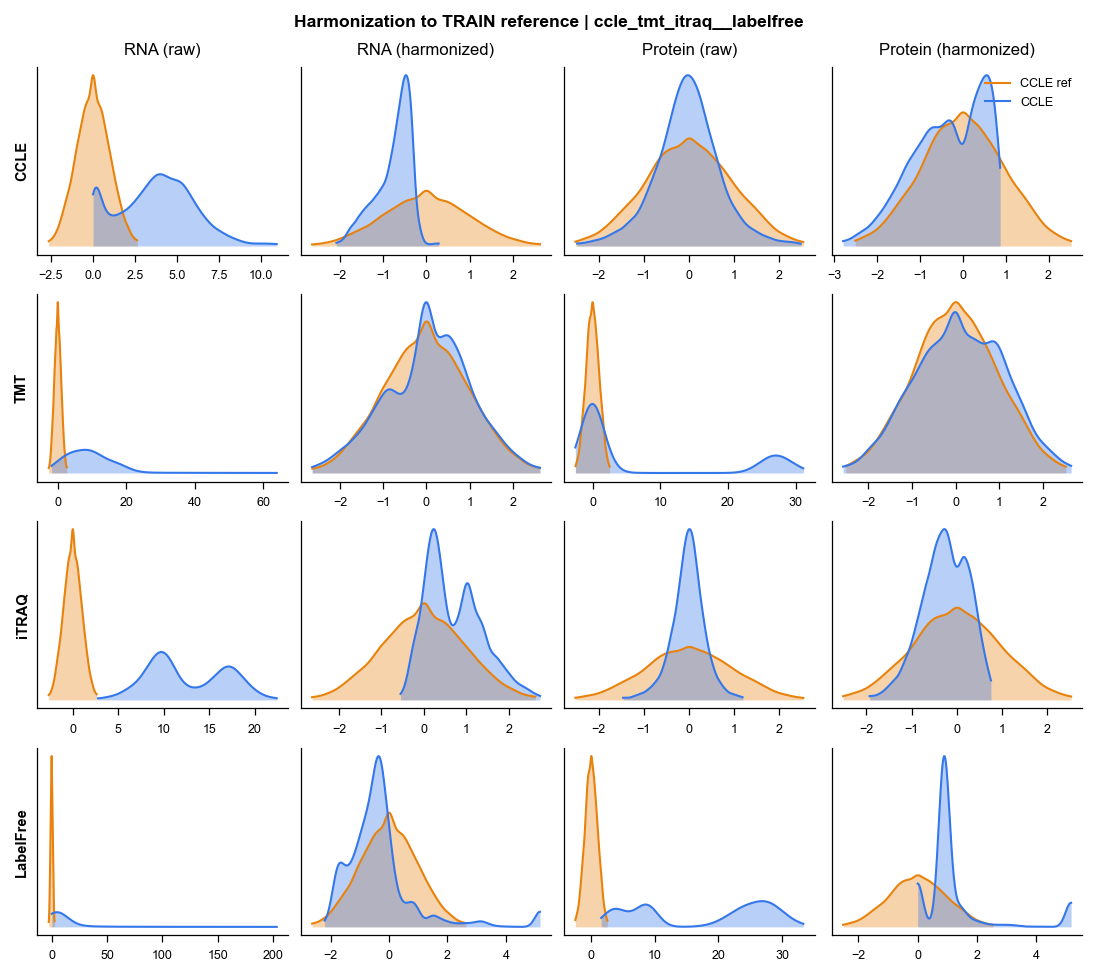

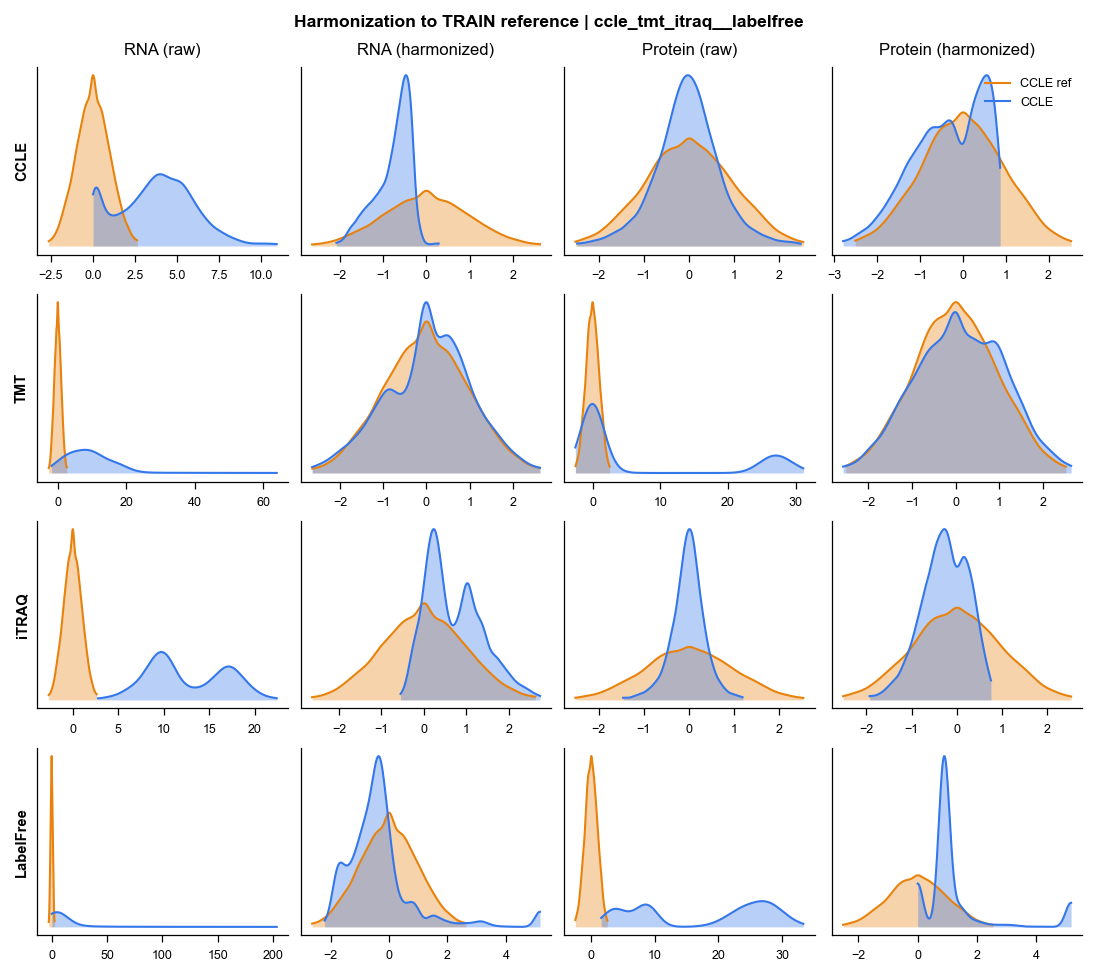

In [9]:
ref_rna = train_rna.to_numpy().ravel(); ref_prot = train_prot.to_numpy().ravel()
raw_vals ={d:{"RNA":raw[d]["RNA"][common_genes].to_numpy().ravel(), "Protein":raw[d]["Protein"][common_prot].to_numpy().ravel()} for d in ALL}
harm_vals={d:{"RNA":harm[d]["RNA"].to_numpy().ravel(), "Protein":harm[d]["Protein"].to_numpy().ravel()} for d in ALL}
ref_vals ={"RNA":H.apply_reference_normalizer(train_rna, rna_params).to_numpy().ravel(),
           "Protein":H.apply_reference_normalizer(train_prot, prot_params).to_numpy().ravel()}
fig = PL.plot_before_after_grid(raw_vals, harm_vals, ref_vals, ALL, title=f"Harmonization to TRAIN reference | {SPLIT_NAME}")
PL.save_publication_figure(fig, FIG_DIR/"harmonization_before_after")
print("figure saved:", FIG_DIR/"harmonization_before_after.pdf"); fig

## 7. Next: HPC training (respects a 20-job cap)
```bash
SPLIT_DIR=data/splits/ccle_tmt_itraq__labelfree MODEL=enet NORMALIZATION=zscore \
  SELECT_K=5000 CV_FOLDS=5 PROTEIN_CHUNKS=20 bash run_train.sh
SPLIT_DIR=data/splits/ccle_tmt_itraq__labelfree MODEL=enet NORMALIZATION=zscore bash run_predict.sh
```
Sweep MODEL in {enet,xgb} and (by re-running this notebook) MODEL_NORM in {zscore,binning,ranking}.